In [94]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

In [95]:
df = pd.read_csv('data.csv', index_col='time')
df

,x1,x2,x3,x4,x5
time,,,,,
0,135,171,60,252,106
24,245,270,113,371,201
48,374,491,186,710,275
72,545,693,269,1088,451
96,839,1163,447,1772,689
120,1544,1788,796,2534,1304
144,2392,3460,1024,4842,2161
168,3433,4704,2131,6478,3386
192,6586,8526,3107,10429,5326


<Axes: xlabel='time'>

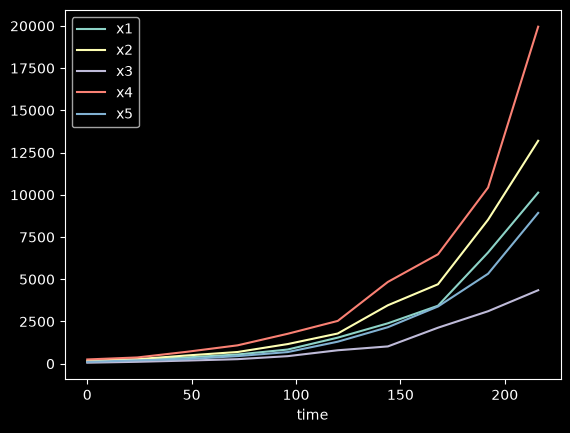

In [96]:
df.plot()

<Axes: xlabel='time'>

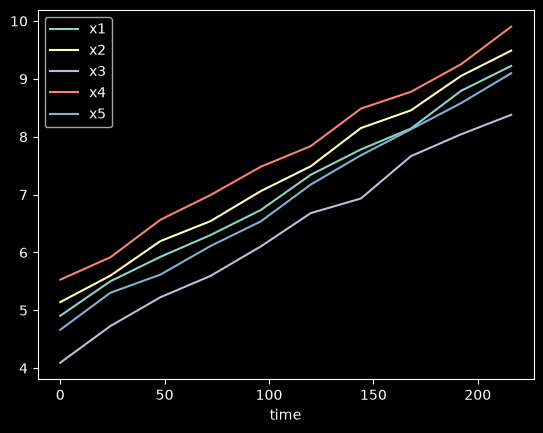

In [97]:
log_df = np.log(df)
log_df.plot()

In [98]:
slopes, intercepts, T_vals, R_vals  = [], [], [], []
t = np.log(df).index.to_numpy(float)

for name in df.columns:
    slope, intercept, r_value, p_value, std_err = stats.linregress(t, np.log(df[name]))

    slopes.append(slope)
    intercepts.append(intercept)
    T_vals.append(np.log(2)/slope)
    R_vals.append(r_value)

result = np.round(pd.DataFrame({
    'r': slopes, 
    'T': T_vals
}), 4)
result

,r,T
0,0.0197,35.1757
1,0.0202,34.3816
2,0.0198,34.9518
3,0.0198,34.9266
4,0.0204,33.9994


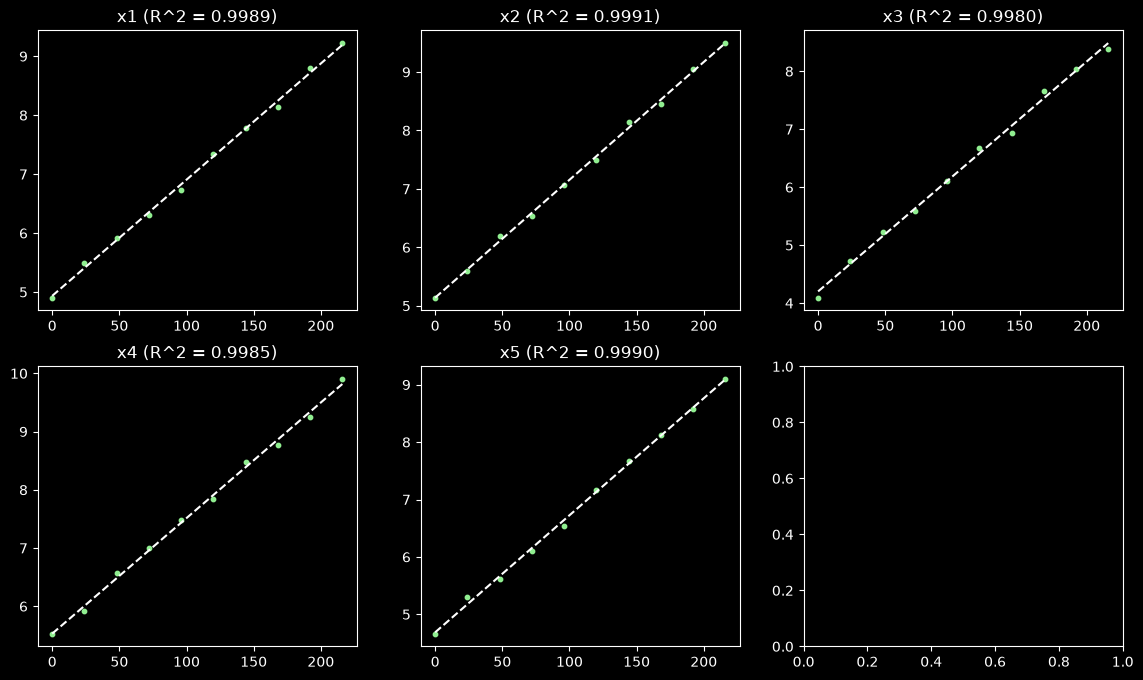

In [99]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for idx in range(5):
    name = f'x{idx + 1}'
    ax = axes[idx]

    ax.scatter(df.index, log_df[name], color='lightgreen', s=10)

    ax.plot(df.index, intercepts[idx] + df.index * slopes[idx], color='white', linestyle='--')

    ax.set_title(f'{name} (R^2 = {R_vals[idx]:.4f})')

In [100]:
result.describe()

,r,T
count,5.000000,5.000000
mean,0.019980,34.687020
std,0.000303,0.482809
min,0.019700,33.999400
25%,0.019800,34.381600
50%,0.019800,34.926600
75%,0.020200,34.951800
max,0.020400,35.175700


In [101]:
median_r = np.median(result['r'])
median_T = np.median(result['T'])
print(f"Медианный r = {median_r:.4f}, медианный T = {median_T:.2f}")

Медианный r = 0.0198, медианный T = 34.93
